<a href="https://colab.research.google.com/github/navyashreenavy/PADV/blob/main/PADV_Activity_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn pyarrow

In [ ]:
import pandas as pd

url = "https://huggingface.co/datasets/hsanchezp/us-dot-flight-delays-2015/resolve/main/flights.parquet"

df = pd.read_parquet(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (5819079, 31)
   YEAR  MONTH  DAY  DAY_OF_WEEK AIRLINE  FLIGHT_NUMBER TAIL_NUMBER  \
0  2015      1    1            4      AS             98      N407AS   
1  2015      1    1            4      AA           2336      N3KUAA   
2  2015      1    1            4      US            840      N171US   
3  2015      1    1            4      AA            258      N3HYAA   
4  2015      1    1            4      AS            135      N527AS   

  ORIGIN_AIRPORT DESTINATION_AIRPORT SCHEDULED_DEPARTURE  ... ARRIVAL_TIME  \
0            ANC                 SEA                0005  ...         0408   
1            LAX                 PBI                0010  ...         0741   
2            SFO                 CLT                0020  ...         0811   
3            LAX                 MIA                0020  ...         0756   
4            SEA                 ANC                0025  ...         0259   

   ARRIVAL_DELAY  DIVERTED CANCELLED  CANCELLATION_REA

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Dataset Shape: (5819079, 31)

Column Names:
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

Missing Values:
YEAR                         0
MONTH                        0
DAY                          0
DAY_OF_WEEK                  0
AIRLINE                      0
FLIGHT_NUMBER                0
TAIL_NUMBER              14721
ORIGIN_AIRPORT               0
DESTINATION_AIRPORT          0
SCHEDULED_DEPARTURE          0
DEPARTURE_TIME           86153
DEPARTURE_DELAY          86153
TAXI_OUT                 89047
WHEELS_OFF               89047
SCHEDULED_TIME  

In [ ]:
# Remove duplicate records
df = df.drop_duplicates()

# Create flight date from YEAR, MONTH, and DAY columns
df["FL_DATE"] = pd.to_datetime(
    pd.DataFrame({
        "year": df["YEAR"],
        "month": df["MONTH"],
        "day": df["DAY"]
    }),
    errors="coerce"
)

# Remove records without a valid flight date
df = df.dropna(subset=["FL_DATE"])

# Create time-based columns
df["Month"] = df["FL_DATE"].dt.month
df["Day"] = df["FL_DATE"].dt.day
df["DayOfWeek"] = df["FL_DATE"].dt.dayofweek

# Create a readable departure hour using SCHEDULED_DEPARTURE column
df["Departure_Hour"] = (
    pd.to_numeric(df["SCHEDULED_DEPARTURE"], errors="coerce")
    .fillna(0)
    .astype(int)
    .floordiv(100)
    .clip(upper=23)
)

print("Cleaned Dataset Shape:", df.shape)
print(df.head())

Cleaned Dataset Shape: (5819079, 36)
   YEAR  MONTH  DAY  DAY_OF_WEEK AIRLINE  FLIGHT_NUMBER TAIL_NUMBER  \
0  2015      1    1            4      AS             98      N407AS   
1  2015      1    1            4      AA           2336      N3KUAA   
2  2015      1    1            4      US            840      N171US   
3  2015      1    1            4      AA            258      N3HYAA   
4  2015      1    1            4      AS            135      N527AS   

  ORIGIN_AIRPORT DESTINATION_AIRPORT SCHEDULED_DEPARTURE  ...  \
0            ANC                 SEA                0005  ...   
1            LAX                 PBI                0010  ...   
2            SFO                 CLT                0020  ...   
3            LAX                 MIA                0020  ...   
4            SEA                 ANC                0025  ...   

  AIR_SYSTEM_DELAY  SECURITY_DELAY  AIRLINE_DELAY LATE_AIRCRAFT_DELAY  \
0              NaN             NaN            NaN                 NaN   

Loading dataset...
Dataset loaded and cleaned automatically!
Accuracy: 0.5820166666666666

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.58      0.68     45395
           1       0.31      0.60      0.41     14605

    accuracy                           0.58     60000
   macro avg       0.56      0.59      0.54     60000
weighted avg       0.69      0.58      0.61     60000



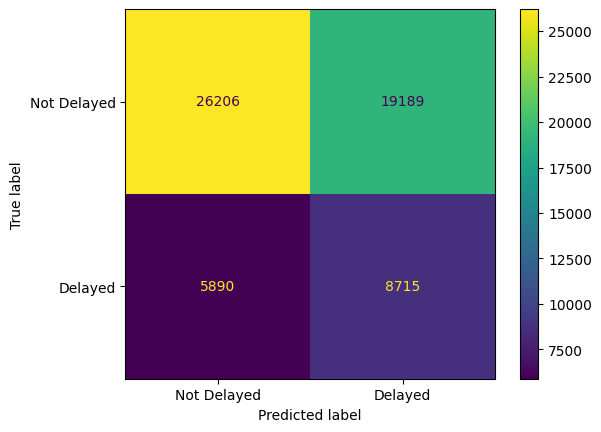

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Automatically load and clean the dataset if 'df' is not defined in memory
if 'df' not in locals() and 'df' not in globals():
    print("Loading dataset...")
    url = "https://huggingface.co/datasets/hsanchezp/us-dot-flight-delays-2015/resolve/main/flights.parquet"
    df = pd.read_parquet(url)
    df = df.drop_duplicates()
    df["FL_DATE"] = pd.to_datetime(
        pd.DataFrame({
            "year": df["YEAR"],
            "month": df["MONTH"],
            "day": df["DAY"]
        }),
        errors="coerce"
    )
    df = df.dropna(subset=["FL_DATE"])
    df["Month"] = df["FL_DATE"].dt.month
    df["Day"] = df["FL_DATE"].dt.day
    df["DayOfWeek"] = df["FL_DATE"].dt.dayofweek
    df["Departure_Hour"] = (
        pd.to_numeric(df["SCHEDULED_DEPARTURE"], errors="coerce")
        .fillna(0)
        .astype(int)
        .floordiv(100)
        .clip(upper=23)
    )
    print("Dataset loaded and cleaned automatically!")

# Convert arrival delay to numeric
df["ARRIVAL_DELAY"] = pd.to_numeric(
    df["ARRIVAL_DELAY"],
    errors="coerce"
)

# Create the target: 1 = delayed, 0 = not delayed
df["Delayed"] = (
    df["ARRIVAL_DELAY"] >= 15
).astype(int)

# Select available features
features = [
    "MONTH",
    "DAY_OF_WEEK",
    "CRS_DEP_TIME",
    "DISTANCE",
    "ORIGIN_AIRPORT",
    "DEST_AIRPORT",
    "AIRLINE"
]

# Check which features exist in the dataset
features = [c for c in features if c in df.columns]

data = df.dropna(
    subset=features + ["ARRIVAL_DELAY"]
).copy()

X = data[features]
y = data["Delayed"]

# Encode categorical variables
X = pd.get_dummies(X, drop_first=True, dtype="uint8")

# Use a manageable sample for initial model training
sample_size = min(300000, len(X))

X_sample = X.iloc[:sample_size]
y_sample = y.iloc[:sample_size]

X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.2,
    random_state=42,
    stratify=y_sample
)

# Train the Decision Tree
model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=["Not Delayed", "Delayed"]
).plot()

import matplotlib.pyplot as plt
plt.show()

In [ ]:
df.to_csv(
    "flight_delays_cleaned.csv",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!


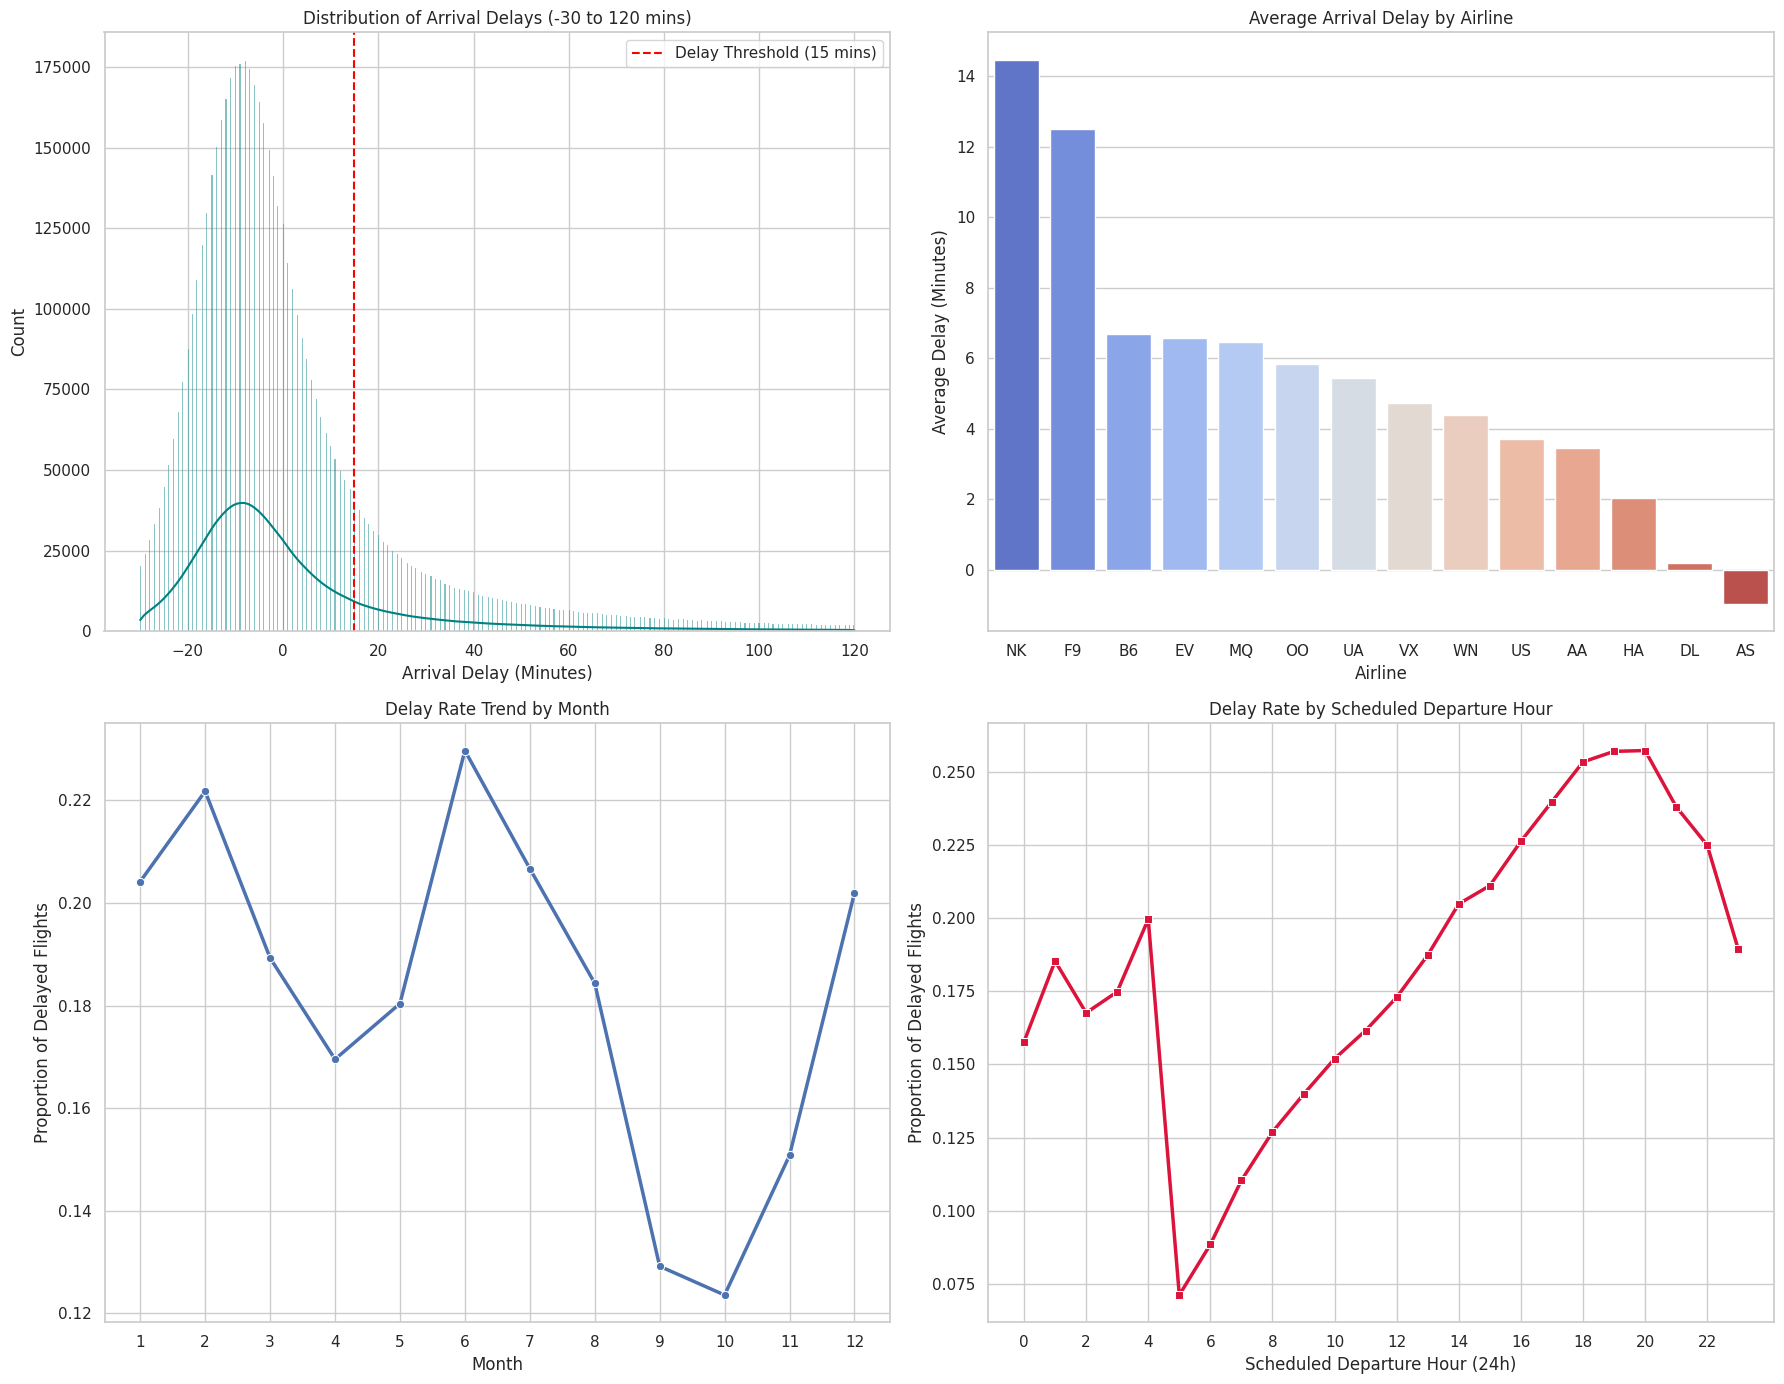

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Safely ensure Departure_Hour and Delayed are present
if "Departure_Hour" not in df.columns:
    df["Departure_Hour"] = (
        pd.to_numeric(df["SCHEDULED_DEPARTURE"], errors="coerce")
        .fillna(0)
        .astype(int)
        .floordiv(100)
        .clip(upper=23)
    )

if "Delayed" not in df.columns:
    df["ARRIVAL_DELAY"] = pd.to_numeric(df["ARRIVAL_DELAY"], errors="coerce")
    df["Delayed"] = (df["ARRIVAL_DELAY"] >= 15).astype(int)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Distribution of Arrival Delays (Clipped for better visualization)
sns.histplot(
    data=df[df["ARRIVAL_DELAY"].between(-30, 120)],
    x="ARRIVAL_DELAY",
    kde=True,
    ax=axes[0, 0],
    color="teal"
)
axes[0, 0].axvline(15, color="red", linestyle="--", label="Delay Threshold (15 mins)")
axes[0, 0].set_title("Distribution of Arrival Delays (-30 to 120 mins)")
axes[0, 0].set_xlabel("Arrival Delay (Minutes)")
axes[0, 0].legend()

# 2. Average Delay by Airline
airline_delay = df.groupby("AIRLINE")["ARRIVAL_DELAY"].mean().reset_index().sort_values("ARRIVAL_DELAY", ascending=False)
sns.barplot(
    data=airline_delay,
    x="AIRLINE",
    y="ARRIVAL_DELAY",
    ax=axes[0, 1],
    hue="AIRLINE",
    legend=False,
    palette="coolwarm"
)
axes[0, 1].set_title("Average Arrival Delay by Airline")
axes[0, 1].set_ylabel("Average Delay (Minutes)")
axes[0, 1].set_xlabel("Airline")

# 3. Delay Rate by Month (using uppercase 'MONTH')
monthly_delays = df.groupby("MONTH")["Delayed"].mean().reset_index()
sns.lineplot(
    data=monthly_delays,
    x="MONTH",
    y="Delayed",
    marker="o",
    ax=axes[1, 0],
    color="b",
    linewidth=2.5
)
axes[1, 0].set_title("Delay Rate Trend by Month")
axes[1, 0].set_ylabel("Proportion of Delayed Flights")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_xticks(range(1, 13))

# 4. Delay Rate by Departure Hour
hourly_delays = df.groupby("Departure_Hour")["Delayed"].mean().reset_index()
sns.lineplot(
    data=hourly_delays,
    x="Departure_Hour",
    y="Delayed",
    marker="s",
    ax=axes[1, 1],
    color="crimson",
    linewidth=2.5
)
axes[1, 1].set_title("Delay Rate by Scheduled Departure Hour")
axes[1, 1].set_ylabel("Proportion of Delayed Flights")
axes[1, 1].set_xlabel("Scheduled Departure Hour (24h)")
axes[1, 1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import pandas as pd

print("Starting Feature Engineering...")

# 1. Create a weekend indicator (Day 6 and 7, which are Saturday and Sunday if 1-indexed in US DOT data)
# In the raw dataset, DAY_OF_WEEK is typically 1 (Monday) to 7 (Sunday)
df["Is_Weekend"] = df["DAY_OF_WEEK"].isin([6, 7]).astype(int)

# 2. Extract Time of Day categories from Departure_Hour
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 22:
        return "Evening"
    else:
        return "Night"

df["Time_of_Day"] = df["Departure_Hour"].apply(get_time_of_day)

# 3. Create Route feature by combining origin and destination
df["Route"] = df["ORIGIN_AIRPORT"].astype(str) + "_" + df["DESTINATION_AIRPORT"].astype(str)

# 4. Target encoding for categorical columns using historical delay rates (to prevent high cardinality explosion)
# We calculate this using a mapping from the dataset to avoid data leakage during cross-validation if needed,
# but for a general baseline, we compute the global delay rate map per airline and route.
airline_delay_rates = df.groupby("AIRLINE")["Delayed"].mean().to_dict()
df["Airline_Delay_Rate"] = df["AIRLINE"].map(airline_delay_rates)

route_delay_rates = df.groupby("Route")["Delayed"].mean().to_dict()
df["Route_Delay_Rate"] = df["Route"].map(route_delay_rates)

print("Feature Engineering completed successfully!")
print("New Columns added:", ["Is_Weekend", "Time_of_Day", "Route", "Airline_Delay_Rate", "Route_Delay_Rate"])
display(df[["AIRLINE", "Route", "Departure_Hour", "Time_of_Day", "Is_Weekend", "Airline_Delay_Rate", "Route_Delay_Rate"]].head())

Starting Feature Engineering...
Feature Engineering completed successfully!
New Columns added: ['Is_Weekend', 'Time_of_Day', 'Route', 'Airline_Delay_Rate', 'Route_Delay_Rate']


,AIRLINE,Route,Departure_Hour,Time_of_Day,Is_Weekend,Airline_Delay_Rate,Route_Delay_Rate
0,AS,ANC_SEA,0,Night,0,0.129561,0.106063
1,AA,LAX_PBI,0,Night,0,0.179452,0.298701
2,US,SFO_CLT,0,Night,0,0.183927,0.129263
3,AA,LAX_MIA,0,Night,0,0.179452,0.210387
4,AS,SEA_ANC,0,Night,0,0.129561,0.178784
